# 18 — Extra: Simulação de Monte Carlo

Ao longo do livro, usamos a simulação o tempo todo: para estimar probabilidades (notebook 05), conferir fórmulas, construir distribuições nulas (notebook 12) e bootstraps (notebook 11). Essa ideia tem nome: **método de Monte Carlo**, batizado em homenagem ao cassino de Mônaco pelos cientistas do Projeto Manhattan, que o usaram nos anos 1940.

A receita é sempre a mesma:
1. Descreva o problema como um **experimento aleatório**.
2. **Sorteie** esse experimento muitas vezes no computador.
3. Resuma os resultados (média, proporção, quantis).

Pela LGN (notebook 10), o resumo converge para a resposta certa; pelo TCL, o erro cai como $1/\sqrt{n}$.

Neste notebook extra vamos:
- Estimar **π** e medir como o erro diminui
- Calcular uma **integral** por Monte Carlo
- Gerar valores de **qualquer distribuição** a partir da uniforme (**transformação inversa**)
- Simular um **problema de risco** com os dados do tips: quanto o garçom ganha de gorjeta num mês?
- Calcular o **valor esperado** de uma decisão sob incerteza

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")

## 2. Estimando π com dardos aleatórios

Jogue dardos ao acaso num quadrado de lado 2 (de −1 a 1 nos dois eixos). A área do quadrado é 4, e a do círculo de raio 1 inscrito nele é $\pi$. Então a **proporção de dardos dentro do círculo** é $\pi / 4$, e

$$\pi \approx 4 \times \text{proporção de dardos dentro do círculo}$$

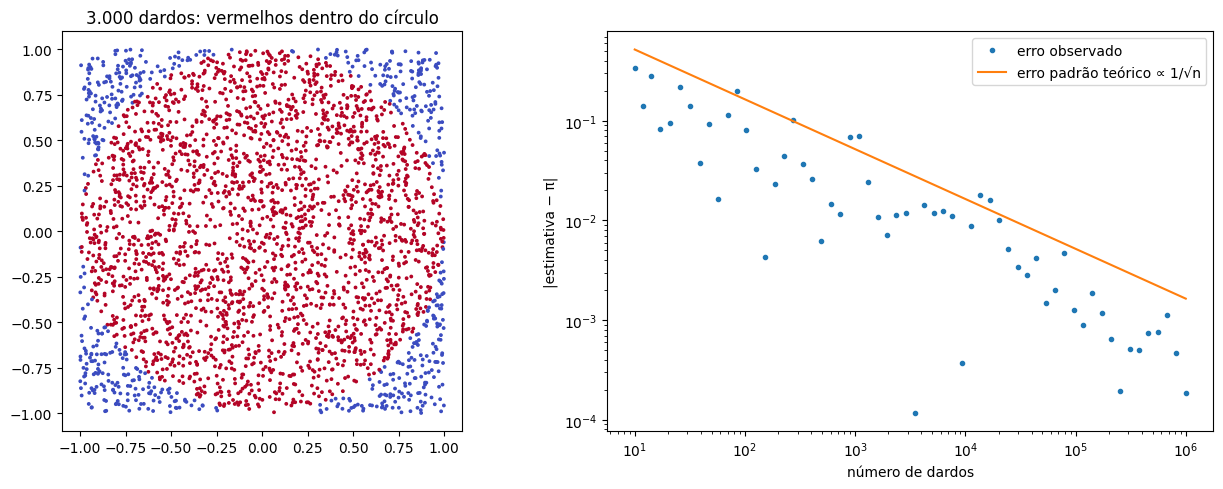

      100 dardos: π ≈ 3.28000   (erro 0.13841)
    10000 dardos: π ≈ 3.14640   (erro 0.00481)
  1000000 dardos: π ≈ 3.14178   (erro 0.00019)


In [2]:
n = 1_000_000
x = rng.uniform(-1, 1, n)
y = rng.uniform(-1, 1, n)
dentro = x**2 + y**2 <= 1    # o ponto está a uma distância de no máximo 1 do centro?

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(x[:3_000], y[:3_000], c=dentro[:3_000], cmap="coolwarm", s=3)
axes[0].set_aspect("equal")
axes[0].set_title("3.000 dardos: vermelhos dentro do círculo")

# O erro da estimativa em função do número de dardos.
tamanhos = np.unique(np.logspace(1, 6, 60).astype(int))   # logspace: valores espaçados em escala log, de 10 a 1.000.000
estimativas = 4 * np.cumsum(dentro)[tamanhos - 1] / tamanhos
axes[1].loglog(tamanhos, np.abs(estimativas - np.pi), "o", markersize=3, label="erro observado")   # loglog: os dois eixos em escala log
axes[1].loglog(tamanhos, 4 * np.sqrt(np.pi / 4 * (1 - np.pi / 4) / tamanhos), label="erro padrão teórico ∝ 1/√n")
axes[1].set_xlabel("número de dardos")
axes[1].set_ylabel("|estimativa − π|")
axes[1].legend()
plt.tight_layout()
plt.show()

for k in [100, 10_000, 1_000_000]:
    print(f"{k:>9} dardos: π ≈ {4 * dentro[:k].mean():.5f}   (erro {abs(4 * dentro[:k].mean() - np.pi):.5f})")

**Conclusão:** com **100** dardos, a estimativa é **3,28** (erro de 0,14); com **10.000**, 3,1464 (erro de 0,005); com **1 milhão**, **3,14178**, com erro de apenas 0,0002. No gráfico da direita, em escala log-log, os erros observados (pontos) oscilam bastante, mas descem acompanhando a reta do erro padrão teórico, que cai como $1/\sqrt{n}$.

É a regra do notebook 10 de novo: cada casa decimal a mais de precisão exige **100 vezes** mais dardos. O Monte Carlo é simples e geral, mas converge devagar.

## 🎓 Conceito: integração por Monte Carlo

A estimativa de π é um caso de **integração por Monte Carlo**. A ideia geral: a integral de uma função $g$ num intervalo $[a, b]$ é o comprimento do intervalo vezes o **valor médio** de $g$ nele. E o valor médio pode ser estimado sorteando pontos uniformes:

$$\int_a^b g(x)\,dx = (b - a) \cdot E[g(U)] \approx (b - a) \cdot \frac{1}{n}\sum_{i=1}^{n} g(u_i), \qquad U \sim \text{Uniforme}(a, b)$$

Para integrais de uma dimensão, existem métodos mais precisos. A vantagem do Monte Carlo aparece com **muitas dimensões**: o erro continua caindo como $1/\sqrt{n}$, não importa quantas variáveis existam, enquanto os métodos de grade ficam impraticáveis.

Vamos calcular $P(-1 \le Z \le 1)$ para a normal padrão, a área que já conhecemos do notebook 08 (0,6827), sem usar a CDF.

In [3]:
g = lambda z: np.exp(-z**2 / 2) / np.sqrt(2 * np.pi)   # a densidade normal padrão
u = rng.uniform(-1, 1, 1_000_000)
valores = g(u)
estimativa = 2 * valores.mean()                       # (b - a) = 2
erro_padrao = 2 * valores.std() / np.sqrt(len(u))
print(f"Monte Carlo: {estimativa:.5f} ± {1.96 * erro_padrao:.5f} (IC 95%)")
print(f"CDF exata:   {stats.norm.cdf(1) - stats.norm.cdf(-1):.5f}")

Monte Carlo: 0.68264 ± 0.00019 (IC 95%)
CDF exata:   0.68269


**Conclusão:** a estimativa por Monte Carlo (**0,68264**, com margem de ±0,00019) e a área exata pela CDF (**0,68269**) concordam, e o valor exato cai dentro do intervalo de confiança da simulação. Repare que a própria simulação informa a sua incerteza, usando o erro padrão das médias. Toda estimativa de Monte Carlo pode (e deve) vir acompanhada do seu erro.

## 🎓 Conceito: transformação inversa

Como o computador sorteia valores de uma exponencial, de uma normal ou de qualquer outra distribuição, se o gerador básico só produz números **uniformes** entre 0 e 1?

O truque mais geral é a **transformação inversa**: se $U$ é uniforme em (0, 1) e $F$ é a CDF da distribuição desejada, então $X = F^{-1}(U)$ tem exatamente essa distribuição. (Em palavras: sorteie um **quantil** ao acaso e devolva o valor correspondente. É o `.ppf` do scipy.)

Para a exponencial com taxa $\lambda$, a CDF é $F(x) = 1 - e^{-\lambda x}$, cuja inversa é $F^{-1}(u) = -\ln(1 - u) / \lambda$.

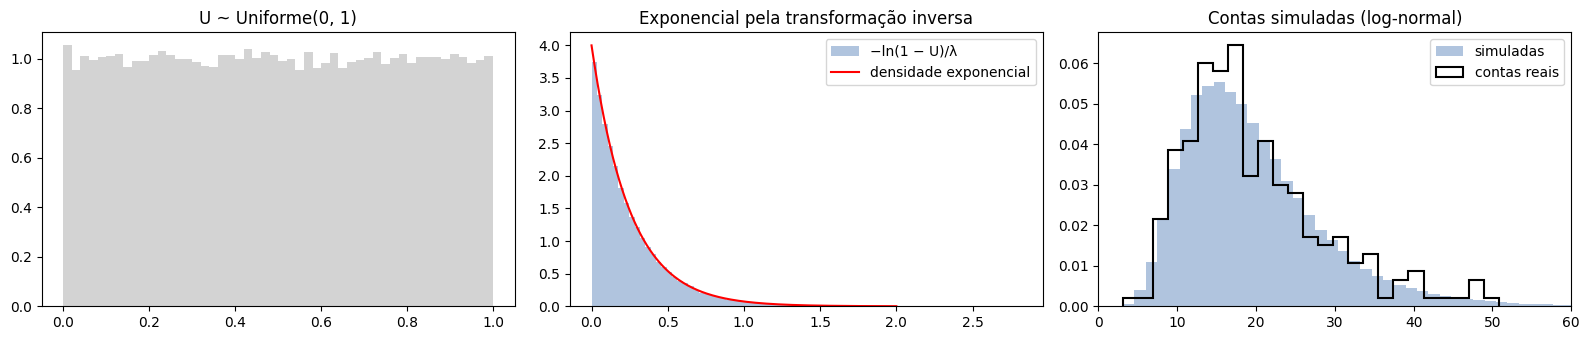

Iguais à mão e pelo scipy? True   média = 0.2503 (teoria: 0.25)


In [4]:
u = rng.random(100_000)
lam = 4
exp_manual = -np.log(1 - u) / lam                 # a inversa da CDF exponencial, à mão
exp_scipy = stats.expon(scale=1 / lam).ppf(u)     # a mesma coisa com o .ppf
# Funciona para qualquer distribuição com .ppf: por exemplo, a log-normal ajustada às contas no notebook 08.
contas_simuladas = stats.lognorm(0.438, scale=np.exp(2.890)).ppf(rng.random(100_000))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
axes[0].hist(u, bins=50, density=True, color="lightgray")
axes[0].set_title("U ~ Uniforme(0, 1)")
axes[1].hist(exp_manual, bins=80, density=True, color="lightsteelblue", label="−ln(1 − U)/λ")
eixo = np.linspace(0, 2, 200)
axes[1].plot(eixo, stats.expon(scale=1 / lam).pdf(eixo), color="red", label="densidade exponencial")
axes[1].set_title("Exponencial pela transformação inversa")
axes[1].legend()
axes[2].hist(contas_simuladas, bins=80, density=True, color="lightsteelblue", label="simuladas")
axes[2].hist(gorjetas["total_bill"], bins=25, density=True, histtype="step", color="black", linewidth=1.5, label="contas reais")
axes[2].set_xlim(0, 60)
axes[2].set_title("Contas simuladas (log-normal)")
axes[2].legend()
plt.tight_layout()
plt.show()

print(f"Iguais à mão e pelo scipy? {np.allclose(exp_manual, exp_scipy)}   média = {exp_manual.mean():.4f} (teoria: {1 / lam})")

**Conclusão:** os números uniformes (esquerda) viraram uma exponencial perfeita (centro): o histograma acompanha a densidade, a média é **0,2503** (teoria: 1/λ = 0,25), e a fórmula à mão dá exatamente os mesmos valores do `.ppf` do scipy. À direita, a mesma técnica gerou 100.000 contas a partir da log-normal ajustada no notebook 08, e o histograma simulado acompanha bem o das 244 contas reais (contorno preto).

Ou seja, um gerador de números uniformes, mais a função quantil, basta para simular qualquer distribuição. É assim que funcionam, por dentro, muitos dos `rng.algumacoisa` que usamos no livro.

## 3. Um problema de risco: as gorjetas de um mês

Agora um problema sem fórmula pronta. O garçom trabalha **20 turnos** por mês. Em cada turno:
- O número de mesas que ele atende é aleatório: **Poisson** com média de 12 mesas (notebook 07).
- A gorjeta de cada mesa é sorteada **das gorjetas reais** do dataset (um bootstrap, notebook 11).

Perguntas: quanto ele ganha de gorjeta num mês típico? Com que chance ganha menos de US\$ 600? E qual o valor do "mês ruim" que acontece 1 vez a cada 20 (o percentil 5)?

Gorjeta mensal média:      US$ 719   (conta direta: 20 × 12 × 3.00 = 720)
Desvio padrão:             US$ 51
Mediana:                   US$ 719
Percentil 5 (mês ruim):    US$ 635
Percentil 95 (mês bom):    US$ 805
P(menos de US$ 600):       0.9%


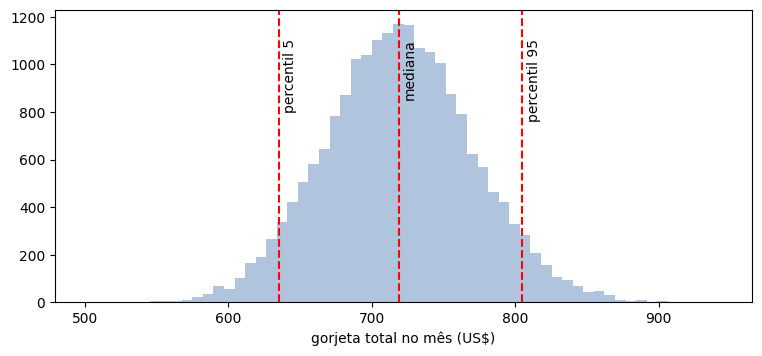

In [5]:
gorjetas_reais = gorjetas["tip"].to_numpy()
turnos, media_mesas = 20, 12


def simular_mes():
    mesas_por_turno = rng.poisson(media_mesas, size=turnos)
    total_mesas = mesas_por_turno.sum()
    return rng.choice(gorjetas_reais, size=total_mesas, replace=True).sum()   # sorteio com reposição


meses = np.array([simular_mes() for _ in range(20_000)])
p5, p50, p95 = np.percentile(meses, [5, 50, 95])
print(f"Gorjeta mensal média:      US$ {meses.mean():.0f}   (conta direta: 20 × 12 × {gorjetas_reais.mean():.2f} = {20 * 12 * gorjetas_reais.mean():.0f})")
print(f"Desvio padrão:             US$ {meses.std():.0f}")
print(f"Mediana:                   US$ {p50:.0f}")
print(f"Percentil 5 (mês ruim):    US$ {p5:.0f}")
print(f"Percentil 95 (mês bom):    US$ {p95:.0f}")
print(f"P(menos de US$ 600):       {np.mean(meses < 600):.1%}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(meses, bins=60, color="lightsteelblue")
for valor, rotulo in [(p5, "percentil 5"), (p50, "mediana"), (p95, "percentil 95")]:
    ax.axvline(valor, color="red", linestyle="--")
    ax.annotate(rotulo, (valor + 3, ax.get_ylim()[1] * 0.9), rotation=90, va="top")
ax.set_xlabel("gorjeta total no mês (US$)")
plt.show()

**Conclusão:** num mês típico, o garçom recebe cerca de **US\$ 719** de gorjeta, o que bate com a conta direta (20 turnos × 12 mesas × US\$ 3,00 = US\$ 720). Mas a simulação mostra o que a conta direta não mostra, a **variação**: o desvio padrão é de **US\$ 51**, um mês ruim (percentil 5) rende **US\$ 635** e um mês bom (percentil 95), **US\$ 805**. A chance de ficar abaixo de US\$ 600 é de só **0,9%**.

O histograma tem forma de sino, apesar de as gorjetas individuais serem assimétricas: o total do mês é a **soma** de cerca de 240 gorjetas, e o TCL (notebook 10) entra em ação. Esse tipo de análise, com quantis da distribuição simulada, é a base do cálculo de risco em finanças e seguros (o "valor em risco").

## 4. Decidindo sob incerteza: vale a pena trabalhar um turno extra?

O restaurante oferece um **turno extra de sábado**, mas o garçom gasta **US\$ 25** de transporte para ir. O movimento de sábado é incerto: num sábado normal (70% das vezes), a média é de 14 mesas; num sábado fraco (30%), de 6 mesas. Usando só as gorjetas reais de **sábado**, qual o ganho esperado do turno extra, e qual a chance de ele **perder** dinheiro?

Ganho líquido esperado:       US$ 9.82
P(perder dinheiro):           29.6%
P(ganhar mais de US$ 30):     10.7%
Conta direta do valor esperado: (0,7 × 14 + 0,3 × 6) × 2.993 − 25 = 9.72


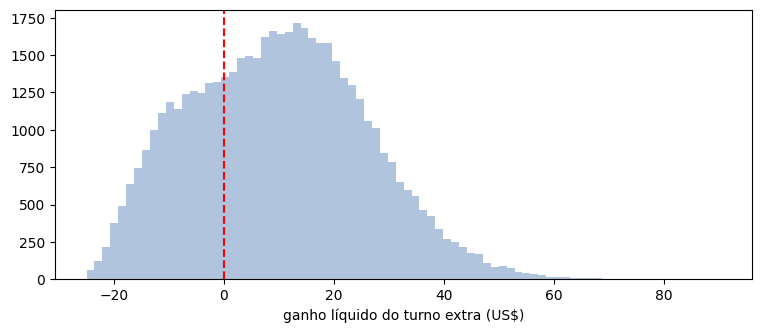

In [6]:
gorjetas_sabado = gorjetas.loc[gorjetas["day"] == "Sat", "tip"].to_numpy()


def simular_turno_extra():
    media = 14 if rng.random() < 0.7 else 6           # primeiro sorteia o tipo de sábado
    mesas = rng.poisson(media)
    return rng.choice(gorjetas_sabado, size=mesas).sum() - 25


ganhos = np.array([simular_turno_extra() for _ in range(50_000)])
print(f"Ganho líquido esperado:       US$ {ganhos.mean():.2f}")
print(f"P(perder dinheiro):           {np.mean(ganhos < 0):.1%}")
print(f"P(ganhar mais de US$ 30):     {np.mean(ganhos > 30):.1%}")
# A conta "de cabeça" para o valor esperado: E[mesas] × E[gorjeta] - 25 (linearidade da esperança, notebook 07).
print(f"Conta direta do valor esperado: (0,7 × 14 + 0,3 × 6) × {gorjetas_sabado.mean():.3f} − 25 = {(0.7 * 14 + 0.3 * 6) * gorjetas_sabado.mean() - 25:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(ganhos, bins=80, color="lightsteelblue")
ax.axvline(0, color="red", linestyle="--")
ax.set_xlabel("ganho líquido do turno extra (US$)")
plt.show()

**Conclusão:** o turno extra vale a pena **em média**: o ganho líquido esperado é de **US\$ 9,82**, muito perto da conta direta pela linearidade da esperança (US\$ 9,72). Mas a média esconde o risco: em **29,6%** das vezes o garçom **perde** dinheiro (as gorjetas não cobrem os US\$ 25 de transporte), e só em 10,7% ganha mais de US\$ 30.

O histograma mostra uma distribuição com um "ombro" à esquerda: é a mistura dos sábados fracos (média de 6 mesas, quase sempre com prejuízo) com os normais. Decidir só pelo valor esperado é razoável para quem pode repetir a aposta muitas vezes; para quem não pode arcar com uma perda, a **probabilidade de perder** pode pesar mais. Monte Carlo entrega as duas informações de uma vez.

## 5. Resumo

**A receita de Monte Carlo:** descreva o problema como um experimento aleatório → sorteie muitas vezes → resuma os resultados. O erro cai como $1/\sqrt{n}$, e pode ser medido com o mesmo erro padrão do notebook 10.

**Conceitos que você aprendeu**
- Estimar **π** e **integrais** por Monte Carlo, e a taxa de convergência $1/\sqrt{n}$.
- A **transformação inversa**: qualquer distribuição a partir da uniforme, com o `.ppf`.
- Simular problemas de **risco** combinando distribuições teóricas (Poisson) e dados reais (bootstrap), e resumi-los com **quantis**.
- Calcular o **valor esperado** e a **probabilidade de perda** de uma decisão.

🔗 **Ponte para o ML:** o Monte Carlo está por trás do bootstrap, dos testes de permutação, do `RandomizedSearchCV`, do *dropout* das redes neurais e dos métodos bayesianos modernos (como o MCMC, que gera amostras de posterioris complicadas demais para as fórmulas do notebook 16).

**Python novo:** `np.logspace`, `ax.loglog`, `.ppf` com valores uniformes, `histtype="step"`, `rng.choice(..., replace=True)`, `ax.get_ylim`.

**Fim do ML-00!** Com a base de estatística e probabilidade completa, siga para o [ML-01 (regressão)](https://github.com/JoaoBLeite/ML-01-Introducao-regressao) e o [ML-02 (classificação)](https://github.com/JoaoBLeite/ML-02-Introducao-classificacao).